# Trader Sentiment and Behavior Analysis
This notebook analyzes how Bitcoin market sentiment (Fear/Greed) affects trader performance and behavior using Hyperliquid trade data.


In [181]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [182]:
# load CSVs
sentiment_df= pd.read_csv('csv_files/fear_greed_index.csv')
trades_df= pd.read_csv('csv_files/historical_data.csv')

# preview data
display(sentiment_df.head())
display(trades_df.head())


,timestamp,value,classification,date
0,1517463000,30,Fear,2018-02-01
1,1517549400,15,Extreme Fear,2018-02-02
2,1517635800,40,Fear,2018-02-03
3,1517722200,24,Extreme Fear,2018-02-04
4,1517808600,11,Extreme Fear,2018-02-05


,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,02-12-2024 22:50,1146.558564,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,02-12-2024 22:50,1289.488521,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12


#### Clean and prepare datasets

In [183]:
# ----------------------------
#  Clean Sentiment Dataset
# ----------------------------


# Convert timestamp (UNIX seconds) → datetime
if np.issubdtype(sentiment_df['timestamp'].dtype, np.number):
    sentiment_df['timestamp'] = pd.to_datetime(sentiment_df['timestamp'], unit='s', errors='coerce')
else:
    sentiment_df['timestamp'] = pd.to_datetime(sentiment_df['timestamp'], errors='coerce')


sentiment_df['date']=pd.to_datetime(sentiment_df['date'], errors='coerce').dt.date

sentiment_df['time_only'] = sentiment_df['timestamp'].dt.time

sentiment_df['classification']=sentiment_df['classification'].astype(str).str.strip().str.title()



# Check for missing values
print("Null values in Sentiment Dataset:")
print(sentiment_df.isna().sum())

# Remove duplicates (by date)
sentiment_df.drop_duplicates(subset=['date'], inplace=True)

# Reset index
sentiment_df.reset_index(drop=True, inplace=True)

# Print summary
print("✅ Sentiment dataset cleaned.")
print(sentiment_df.info())
display(sentiment_df.head())

Null values in Sentiment Dataset:
timestamp         0
value             0
classification    0
date              0
time_only         0
dtype: int64
✅ Sentiment dataset cleaned.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       2644 non-null   datetime64[ns]
 1   value           2644 non-null   int64         
 2   classification  2644 non-null   object        
 3   date            2644 non-null   object        
 4   time_only       2644 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 103.4+ KB
None


,timestamp,value,classification,date,time_only
0,2018-02-01 05:30:00,30,Fear,2018-02-01,05:30:00
1,2018-02-02 05:30:00,15,Extreme Fear,2018-02-02,05:30:00
2,2018-02-03 05:30:00,40,Fear,2018-02-03,05:30:00
3,2018-02-04 05:30:00,24,Extreme Fear,2018-02-04,05:30:00
4,2018-02-05 05:30:00,11,Extreme Fear,2018-02-05,05:30:00


In [184]:
# ----------------------------
# Clean Trades Dataset
# ----------------------------


# Standardize column names
trades_df.columns=trades_df.columns.str.lower().str.strip().str.replace(' ','_')

# Convert both timestamp columns
trades_df['timestamp_ist'] = pd.to_datetime(trades_df['timestamp_ist'], format='%d-%m-%Y %H:%M', errors='coerce')

# If 'timestamp' is a UNIX-like integer
if np.issubdtype(trades_df['timestamp'].dtype, np.number):
    trades_df['timestamp'] = pd.to_datetime(trades_df['timestamp'], unit='s', errors='coerce')
else:
    trades_df['timestamp'] = pd.to_datetime(trades_df['timestamp'], errors='coerce')

# Compare to see if they’re essentially the same
time_diff = (trades_df['timestamp_ist'] - trades_df['timestamp']).dropna().dt.total_seconds().abs().mean()
print(f"Average time difference between timestamp_ist and timestamp: {time_diff:.2f} seconds")

# The difference is negligible so drop 'timestamp' and use 'timestamp_ist', since it has timezone context

trades_df.drop(columns=['timestamp'], inplace=True)
print("Dropped 'timestamp' — kept 'timestamp_ist' as the main time reference.")

# Add date & time-only columns for flexibility
trades_df['date'] = trades_df['timestamp_ist'].dt.date
trades_df['time_only'] = trades_df['timestamp_ist'].dt.time

# Create a date column for merging
trades_df['date']=trades_df['timestamp_ist'].dt.date



Average time difference between timestamp_ist and timestamp: nan seconds
Dropped 'timestamp' — kept 'timestamp_ist' as the main time reference.


In [185]:
# Check for missing values
print("Null values in trades dataset:")
print(trades_df.isna().sum())

Null values in trades dataset:
account             0
coin                0
execution_price     0
size_tokens         0
size_usd            0
side                0
timestamp_ist       0
start_position      0
direction           0
closed_pnl          0
transaction_hash    0
order_id            0
crossed             0
fee                 0
trade_id            0
date                0
time_only           0
dtype: int64


In [186]:
# Convert numeric columns safely
numeric_cols = ['execution_price', 'size_tokens', 'size_usd', 'closed_pnl','start_position','fee'] 
for col in numeric_cols:
    trades_df[col] = pd.to_numeric(trades_df[col], errors='coerce')


(trades_df[['execution_price', 'size_tokens', 'size_usd']] <= 0).sum()

#If USD value is 0, it’s almost always an invalid trade.
trades_df=trades_df[trades_df['size_usd']>0]            # keep only positive values

trades_df['is_profitable'] = (trades_df['closed_pnl'] > 0).astype(int)


trades_df['crossed'] = trades_df['crossed'].astype(str).str.strip().str.lower().map({'true': True, 'false': False})


# Clean categorical/text columns
text_cols = ['side', 'direction']
for col in text_cols:
    trades_df[col] = trades_df[col].astype(str).str.strip().str.upper()

# If both are same, drop one
if (trades_df['side'] == trades_df['direction']).all():
    trades_df.drop(columns=['direction'], inplace=True)



In [187]:
# Drop duplicates and reset index
trades_df.drop_duplicates(inplace=True)
trades_df.reset_index(drop=True, inplace=True)

print("\n✅ Trader dataset cleaned and ready for merge.")
print(trades_df.info())
display(trades_df.head())


✅ Trader dataset cleaned and ready for merge.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211181 entries, 0 to 211180
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   account           211181 non-null  object        
 1   coin              211181 non-null  object        
 2   execution_price   211181 non-null  float64       
 3   size_tokens       211181 non-null  float64       
 4   size_usd          211181 non-null  float64       
 5   side              211181 non-null  object        
 6   timestamp_ist     211181 non-null  datetime64[ns]
 7   start_position    211181 non-null  float64       
 8   direction         211181 non-null  object        
 9   closed_pnl        211181 non-null  float64       
 10  transaction_hash  211181 non-null  object        
 11  order_id          211181 non-null  int64         
 12  crossed           211181 non-null  bool          
 13  fee         

,account,coin,execution_price,size_tokens,size_usd,side,timestamp_ist,start_position,direction,closed_pnl,transaction_hash,order_id,crossed,fee,trade_id,date,time_only,is_profitable
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,2024-12-02 22:50:00,0.000000,BUY,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,2024-12-02,22:50:00,0
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,2024-12-02 22:50:00,986.524596,BUY,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,2024-12-02,22:50:00,0
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,2024-12-02 22:50:00,1002.518996,BUY,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,2024-12-02,22:50:00,0
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,2024-12-02 22:50:00,1146.558564,BUY,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,2024-12-02,22:50:00,0
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,2024-12-02 22:50:00,1289.488521,BUY,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,2024-12-02,22:50:00,0


In [188]:
# Now merge using 'date' as the key
merged_df = pd.merge(trades_df, sentiment_df[['date', 'classification']], on='date', how='left')

# Optional: Drop identifiers
merged_df.drop(columns=['account', 'transaction_hash', 'order_id', 'trade_id'], inplace=True)

print("✅ Merge successful!")
print("Merged dataset shape:", merged_df.shape)
display(merged_df.head())


✅ Merge successful!
Merged dataset shape: (211181, 15)


,coin,execution_price,size_tokens,size_usd,side,timestamp_ist,start_position,direction,closed_pnl,crossed,fee,date,time_only,is_profitable,classification
0,@107,7.9769,986.87,7872.16,BUY,2024-12-02 22:50:00,0.000000,BUY,0.0,True,0.345404,2024-12-02,22:50:00,0,Extreme Greed
1,@107,7.9800,16.00,127.68,BUY,2024-12-02 22:50:00,986.524596,BUY,0.0,True,0.005600,2024-12-02,22:50:00,0,Extreme Greed
2,@107,7.9855,144.09,1150.63,BUY,2024-12-02 22:50:00,1002.518996,BUY,0.0,True,0.050431,2024-12-02,22:50:00,0,Extreme Greed
3,@107,7.9874,142.98,1142.04,BUY,2024-12-02 22:50:00,1146.558564,BUY,0.0,True,0.050043,2024-12-02,22:50:00,0,Extreme Greed
4,@107,7.9894,8.73,69.75,BUY,2024-12-02 22:50:00,1289.488521,BUY,0.0,True,0.003055,2024-12-02,22:50:00,0,Extreme Greed


In [189]:
for cols in merged_df.columns:
    if merged_df[cols].isna().sum()!=0:
        print(cols, merged_df[cols].isna().sum())

classification 6


Since we merged on 'date', that means 6 dates that are present on trades dataset did not exist in the sentiment dataset.

Let’s check which dates have NaN sentiment:

In [190]:
# Check missing sentiment
merged_df.loc[merged_df['classification'].isna(), ['date']].drop_duplicates()


,date
727,2024-10-26


So trades happened on 2024-10-26, but the sentiment dataset does not contain that date.

This can happen because:

- The sentiment index wasn’t published that day (weekend / outage).

- Or the timestamp alignment (timezone difference) shifted the date by a few hours.



Sentiment doesn’t change dramatically from one day to the next.

So we can use the most recent known sentiment (previous day’s value).

In [191]:
# Sort to ensure proper chronological fill
merged_df = merged_df.sort_values('date')
# Handle NaN sentiment
merged_df['classification'] = merged_df['classification'].ffill()

# Verify after fixing
print("Remaining NaN in classification:", merged_df['classification'].isna().sum())

Remaining NaN in classification: 0


Let pnl_pct denote the percentage return (or loss) on each trade 

The profit percentage is given by

$$
\text{pnl\_pct} = \frac{\text{closed\_pnl}}{\text{size\_usd}} \times 100
$$


In [192]:
# Create pnl_pct
merged_df['pnl_pct'] = merged_df['closed_pnl'] / merged_df['size_usd']


#### Frequency of sentiment labels

Let's check sentiment distribution

In [193]:
print(merged_df['classification'].value_counts())


classification
Fear             61826
Greed            50289
Extreme Greed    39980
Neutral          37686
Extreme Fear     21400
Name: count, dtype: int64


### Trade Volume and Sentiment Distribution

- The dataset shows most trades occur under Fear (61,826) and Greed (50,289) conditions, followed by Extreme Greed (39,980), Neutral (37,686), and Extreme Fear (21,400).

- This suggests that trading activity is highest during fear-driven markets, potentially reflecting higher volatility and opportunity for active traders.

#### Basic statistics per sentiment group

Now let us do the summary stats grouped by sentiment to understand average performance and trading behavior during “Fear” vs “Greed”.

This shows whether traders tend to be more or less profitable during Fear vs Greed days.***

In [194]:
# Grouped summary by sentiment
grouped = merged_df.groupby('classification').agg(
    n_trades = ('pnl_pct','size'),
    mean_closed_pnl = ('closed_pnl','mean'),
    median_closed_pnl = ('closed_pnl','median'),
    mean_pnl_pct = ('pnl_pct','mean'),
    win_rate = ('is_profitable','mean'),
    avg_size_usd = ('size_usd','mean'),
    avg_execution_price = ('execution_price','mean'),
    avg_fee = ('fee','mean'),
).round(4).sort_values(('mean_pnl_pct'), ascending=False)
display(grouped)


,n_trades,mean_closed_pnl,median_closed_pnl,mean_pnl_pct,win_rate,avg_size_usd,avg_execution_price,avg_fee
classification,,,,,,,,
Extreme Greed,39980,67.9132,0.0,0.0400,0.4651,3113.1857,6084.0214,0.6761
Greed,50289,43.6000,0.0,0.0197,0.3851,5740.2447,13415.0102,1.2549
Fear,61826,54.3001,0.0,0.0154,0.4208,7817.5006,14155.1382,1.4954
Neutral,37686,34.3077,0.0,0.0099,0.3970,4782.7327,12393.6928,1.0448
Extreme Fear,21400,34.5379,0.0,0.0043,0.3706,5349.7318,7054.7951,1.1163



💰 Profitability (mean_closed_pnl & pnl%)

- Extreme Greed traders earned the highest mean PnL (≈ 67.9 USD) and highest mean PnL% (0.04%).

- Extreme Fear and Neutral had the lowest returns and win rates (~0.37–0.40).

- Mean PnL % increases from 0.0043 (Extreme Fear) → 0.0154 (Fear) → 0.0197 (Greed) → 0.0400 (Extreme Greed), showing that profitability improves with positive sentiment.

- All medians are 0, meaning that at least half the trades result in break-even or losses. This highlights asymmetric return distributions (few large winners, many small or zero outcomes).

- win_rate slightly fluctuates between 37% (Extreme Fear) and 46% (Extreme Greed), indicating that even in optimistic markets, more than half of trades are not profitable.

Interpretation:

- Traders tend to take higher risks (and larger profits) during Extreme Greed phases.

- During Fear, they reduce position size and profitability.

 #### Trading volume patterns

 Shows how much traders actually trade during different sentiment phases

In [195]:
# Total volume traded per sentiment
volume_by_sentiment = merged_df.groupby('classification').agg({
    'size_usd': ['sum', 'mean', 'median'],
    'size_tokens': ['sum', 'mean'],
    'fee': 'sum'
}).round(2)

volume_by_sentiment.columns = ['_'.join(col).strip() for col in volume_by_sentiment.columns]
print("\nVolume Statistics by Sentiment:")
display(volume_by_sentiment)


Volume Statistics by Sentiment:


,size_usd_sum,size_usd_mean,size_usd_median,size_tokens_sum,size_tokens_mean,fee_sum
classification,,,,,,
Extreme Fear,1.144843e+08,5349.73,766.15,3.586412e+07,1675.89,23888.63
Extreme Greed,1.244652e+08,3113.19,500.06,3.532260e+08,8835.07,27030.67
Fear,4.833248e+08,7817.50,736.14,1.850560e+08,2993.17,92456.95
Greed,2.886712e+08,5740.24,555.00,2.372275e+08,4717.29,63107.20
Neutral,1.802421e+08,4782.73,547.66,1.651916e+08,4383.37,39374.27


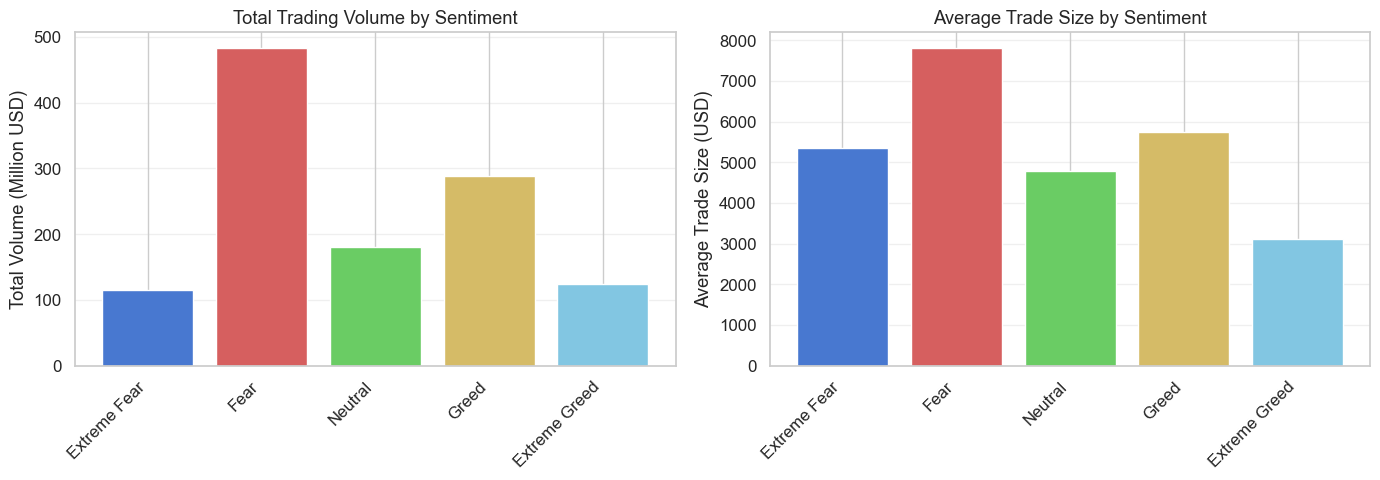

In [196]:
# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
my_colors = ['b','r', 'g', 'y', 'c','m']

# Total volume
sentiment_order = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
vol_data = merged_df.groupby('classification')['size_usd'].sum().reindex(sentiment_order)
axes[0].bar(range(len(vol_data)), vol_data.values / 1e6, color=my_colors)
axes[0].set_xticks(range(len(vol_data)))
axes[0].set_xticklabels(sentiment_order, rotation=45, ha='right')
axes[0].set_ylabel('Total Volume (Million USD)')
axes[0].set_title('Total Trading Volume by Sentiment')
axes[0].grid(axis='y', alpha=0.3)

# Average trade size
avg_size = merged_df.groupby('classification')['size_usd'].mean().reindex(sentiment_order)
axes[1].bar(range(len(avg_size)), avg_size.values, color=my_colors)
axes[1].set_xticks(range(len(avg_size)))
axes[1].set_xticklabels(sentiment_order, rotation=45, ha='right')
axes[1].set_ylabel('Average Trade Size (USD)')
axes[1].set_title('Average Trade Size by Sentiment')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/TradingVol_by_sentiment.png')
plt.show()

- **Fear drives both volume and size:** Traders appear most active and commit larger amounts per trade during fearful market conditions, possibly attempting to capitalize on perceived opportunities or protect positions.

- **Extreme Greed shows caution:** Extreme Greed shows low volume with small trades, suggesting traders become more cautious with smaller positions when sentiment is extremely positive.

- **Greed vs Extreme Greed disparity:** Traders reduce exposure during extreme optimism.

#### Buy/Sell behavior

Reveals if traders are more aggressive (buying) or defensive (selling) during fear/greed

In [197]:
# Calculate buy/sell ratios
buy_sell = merged_df.groupby(['classification', 'side']).size().unstack(fill_value=0)
buy_sell['buy_ratio'] = buy_sell['BUY'] / (buy_sell['BUY'] + buy_sell['SELL'])
buy_sell['sell_ratio'] = buy_sell['SELL'] / (buy_sell['BUY'] + buy_sell['SELL'])

print("\nBuy/Sell Distribution:")
display(buy_sell)


Buy/Sell Distribution:


side,BUY,SELL,buy_ratio,sell_ratio
classification,,,,
Extreme Fear,10935,10465,0.510981,0.489019
Extreme Greed,17940,22040,0.448724,0.551276
Fear,30270,31556,0.489600,0.510400
Greed,24582,25707,0.488815,0.511185
Neutral,18969,18717,0.503343,0.496657


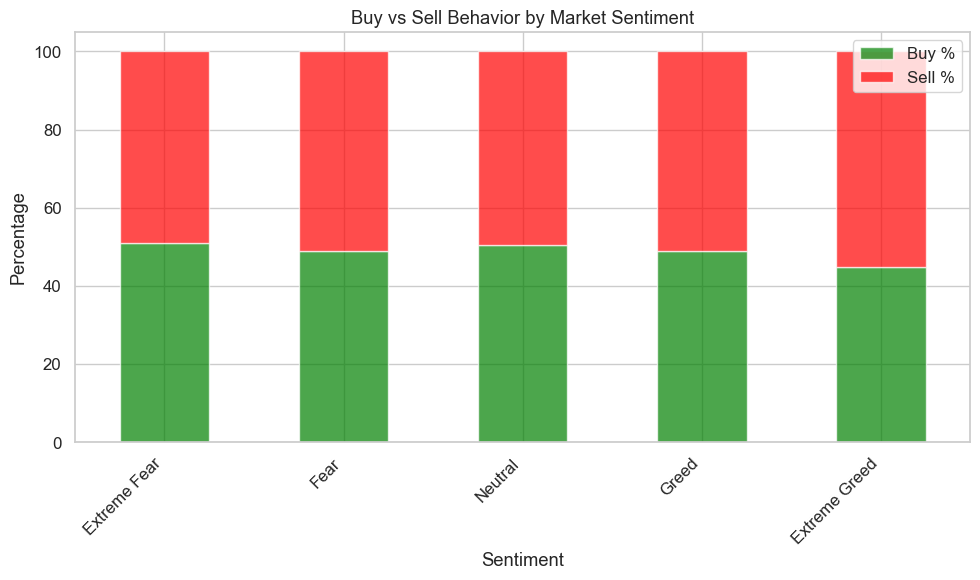

In [198]:
# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
buy_sell_pct = buy_sell[['buy_ratio', 'sell_ratio']].reindex(sentiment_order) * 100
buy_sell_pct.plot(kind='bar', stacked=True, ax=ax, color=['green', 'red'], alpha=0.7)
ax.set_ylabel('Percentage')
ax.set_xlabel('Sentiment')
ax.set_title('Buy vs Sell Behavior by Market Sentiment')
ax.legend(['Buy %', 'Sell %'])
ax.set_xticklabels(sentiment_order, rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/BuySell_by_sentiment.png')
plt.show()

- Contrarian behavior is evident at extremes.

- Market is generally balanced (48.9–51.1%) except for Extreme Greed.

- Buy/sell decisions are moderately influenced by sentiment.

#### Profitability Deep Dive 

Separates winning from losing trades to understand risk-reward dynamics

In [199]:
# Separate winning and losing trades
profitable_trades = merged_df[merged_df['closed_pnl'] > 0].groupby('classification').agg({
    'closed_pnl': ['mean', 'median', 'sum'],
    'pnl_pct': 'mean'
})
profitable_trades.columns = ['_'.join(col).strip() for col in profitable_trades.columns]

losing_trades = merged_df[merged_df['closed_pnl'] < 0].groupby('classification').agg({
    'closed_pnl': ['mean', 'median', 'sum'],
    'pnl_pct': 'mean'
})
losing_trades.columns = ['_'.join(col).strip() for col in losing_trades.columns]

print("\nProfitable Trades Stats:")
display(profitable_trades.reindex(sentiment_order))

print("\nLosing Trades Stats:")
display(losing_trades.reindex(sentiment_order))

# Risk-Reward Ratio
risk_reward = pd.DataFrame({
    'avg_win': profitable_trades['closed_pnl_mean'],
    'avg_loss': abs(losing_trades['closed_pnl_mean']),
})
risk_reward['risk_reward_ratio'] = risk_reward['avg_win'] / risk_reward['avg_loss']
print("\nRisk-Reward Ratio by Sentiment:")
display(risk_reward.reindex(sentiment_order))


Profitable Trades Stats:


,closed_pnl_mean,closed_pnl_median,closed_pnl_sum,pnl_pct_mean
classification,,,,
Extreme Fear,173.424767,17.361168,1.375432e+06,0.046922
Fear,151.840935,9.903600,3.950749e+06,0.041919
Neutral,112.439432,8.603440,1.682206e+06,0.036592
Greed,167.903697,12.735453,3.251287e+06,0.065558
Extreme Greed,160.593269,12.233936,2.986071e+06,0.110286



Losing Trades Stats:


,closed_pnl_mean,closed_pnl_median,closed_pnl_sum,pnl_pct_mean
classification,,,,
Extreme Fear,-257.099629,-24.650581,-6.363216e+05,-0.112993
Fear,-156.662401,-8.867057,-5.935938e+05,-0.036377
Neutral,-121.727849,-8.760710,-3.892857e+05,-0.054098
Greed,-181.967329,-10.756418,-1.058686e+06,-0.047812
Extreme Greed,-119.920289,-4.245000,-2.708999e+05,-0.199364



Risk-Reward Ratio by Sentiment:


,avg_win,avg_loss,risk_reward_ratio
classification,,,
Extreme Fear,173.424767,257.099629,0.674543
Fear,151.840935,156.662401,0.969224
Neutral,112.439432,121.727849,0.923695
Greed,167.903697,181.967329,0.922713
Extreme Greed,160.593269,119.920289,1.339167


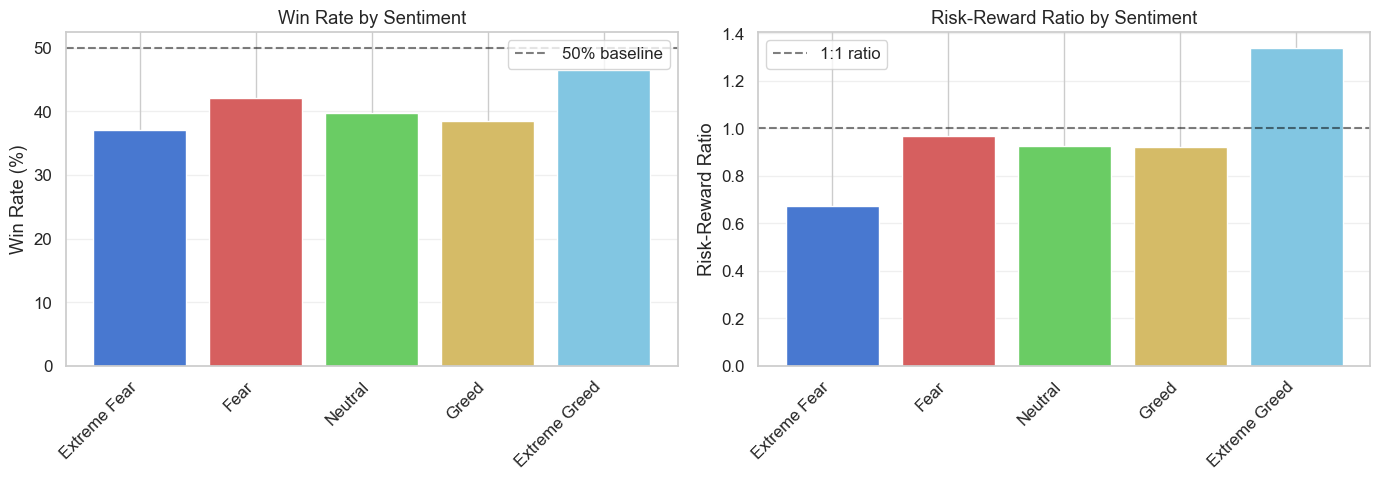

In [200]:
# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Win rates
win_rates = merged_df.groupby('classification')['is_profitable'].mean().reindex(sentiment_order) * 100
axes[0].bar(range(len(win_rates)), win_rates.values, color=my_colors)
axes[0].axhline(50, color='black', linestyle='--', alpha=0.5, label='50% baseline')
axes[0].set_xticks(range(len(win_rates)))
axes[0].set_xticklabels(sentiment_order, rotation=45, ha='right')
axes[0].set_ylabel('Win Rate (%)')
axes[0].set_title('Win Rate by Sentiment')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Risk-Reward
rr_plot = risk_reward['risk_reward_ratio'].reindex(sentiment_order)
axes[1].bar(range(len(rr_plot)), rr_plot.values, color=my_colors)
axes[1].axhline(1, color='black', linestyle='--', alpha=0.5, label='1:1 ratio')
axes[1].set_xticks(range(len(rr_plot)))
axes[1].set_xticklabels(sentiment_order, rotation=45, ha='right')
axes[1].set_ylabel('Risk-Reward Ratio')
axes[1].set_title('Risk-Reward Ratio by Sentiment')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/Profitability_by_sentiment.png')
plt.show()

- **Extreme Greed paradox:** Best risk-reward (1.34) but losses on certain trades are high.

- **Fear is most profitable:** Fear sentiment generated the highest total profits at $3.95M despite only 42% win rate. This is due to high trade volume.

- **Extreme Fear is challenging:** Losses outweigh wins, requiring strong risk management.

#### Time based patterns

Identifies which hours of the day are most profitable for different sentiments

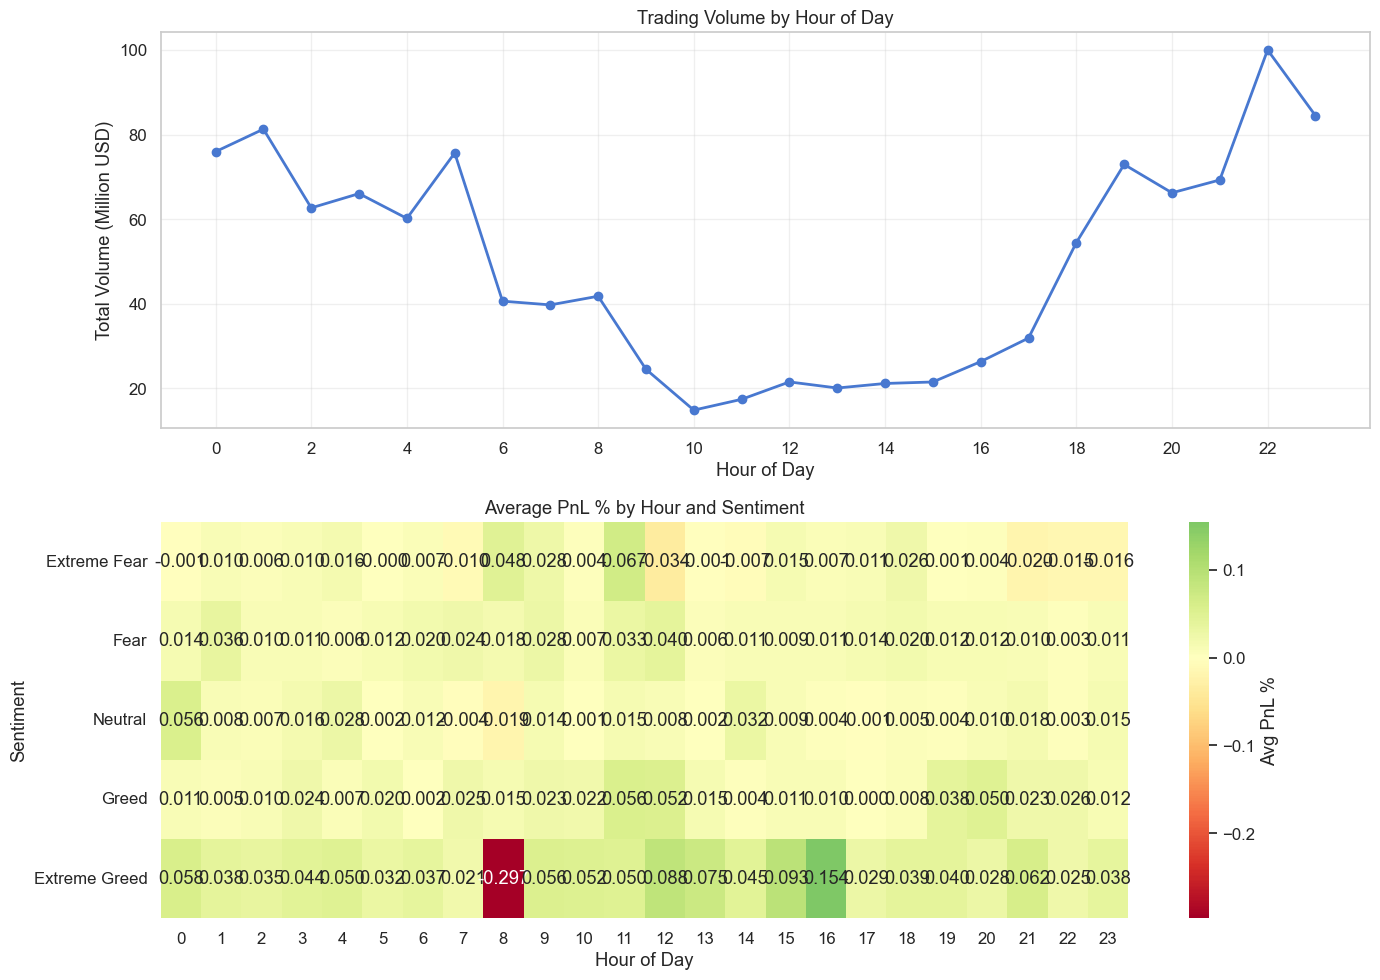

In [201]:
# Add hour of day
merged_df['hour'] = merged_df['timestamp_ist'].dt.hour

# Trading activity by hour and sentiment
hourly_sentiment = merged_df.groupby(['hour', 'classification']).size().unstack(fill_value=0)

# Visualize
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Trading volume by hour
hourly_volume = merged_df.groupby('hour')['size_usd'].sum() / 1e6
axes[0].plot(hourly_volume.index, hourly_volume.values, marker='o', linewidth=2)
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Total Volume (Million USD)')
axes[0].set_title('Trading Volume by Hour of Day')
axes[0].grid(alpha=0.3)
axes[0].set_xticks(range(0, 24, 2))

# Heatmap of sentiment by hour
hourly_pnl = merged_df.groupby(['hour', 'classification'])['pnl_pct'].mean().unstack()
hourly_pnl = hourly_pnl[sentiment_order]
sns.heatmap(hourly_pnl.T, cmap='RdYlGn', center=0, annot=True, fmt='.3f', 
            cbar_kws={'label': 'Avg PnL %'}, ax=axes[1])
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Sentiment')
axes[1].set_title('Average PnL % by Hour and Sentiment')

plt.tight_layout()
plt.savefig('outputs/Temporalpattern_by_sentiment.png')
plt.show()

**The Extreme Greed Hour 8 Anomaly:** At 8:00 am IST, Extreme Greed shows catastrophic -0.29% average loss. This hour shows moderate volume (~40M USD), not particularly low. A Possible explanation could be
- Time-zone overlap and low liquidity
- Strategic manipulation (bull trap)

Extreme Greed strategies may work better in quieter markets with less competition


**Coin-Specific Analysis**

Shows if certain coins perform better during specific market moods

In [202]:
# Top traded coins
top_coins = merged_df['coin'].value_counts().head(10)
print("\nTop 10 Most Traded Coins:")
display(top_coins)

# Performance by coin and sentiment for top 5
top_5_coins = top_coins.head(5).index
coin_sentiment_perf = merged_df[merged_df['coin'].isin(top_5_coins)].groupby(['coin', 'classification']).agg({
    'pnl_pct': 'mean',
    'is_profitable': 'mean',
    'size_usd': 'mean'
}).round(4)


print("\nTop 5 Coins Performance by Sentiment:")
display(coin_sentiment_perf)


Top 10 Most Traded Coins:


coin
HYPE         68005
@107         29992
BTC          26064
ETH          11158
SOL          10691
FARTCOIN      4650
MELANIA       4428
PURR/USDC     2773
WLD           1983
SUI           1979
Name: count, dtype: int64


Top 5 Coins Performance by Sentiment:


pnl_pct  is_profitable    size_usd
coin classification                                    
@107 Extreme Fear    -0.0467         0.2475   1635.4310
     Extreme Greed    0.1313         0.5617   1966.0265
     Fear            -0.0011         0.4143   1498.0606
     Greed            0.0599         0.4589   2015.2396
     Neutral          0.0270         0.4010   1833.1773
BTC  Extreme Fear     0.0012         0.3076  20822.3928
     Extreme Greed    0.0022         0.3399  18013.9281
     Fear             0.0022         0.3855  30487.5545
     Greed            0.0003         0.3322  22693.3403
     Neutral          0.0013         0.3288  20699.9195
ETH  Extreme Fear     0.0146         0.5571   5542.0338
     Extreme Greed    0.0002         0.2554   7910.0347
     Fear             0.0181         0.4168  13907.1407
     Greed            0.0069         0.2594  10443.5613
     Neutral          0.0049         0.4617  13356.4097
HYPE Extreme Fear     0.0142         0.3969   2846.1937
     Extreme Greed    0.0127         0.4105   1774.9057
     Fear             0.0125         0.4343   2265.6623
     Greed            0.0093         0.3715   1736.1092
     Neutral          0.0085         0.4130   1591.4908
SOL  Extreme Fear     0.0023         0.3120  13973.0350
     Extreme Greed    0.0035         0.2561   4203.1433
     Fear             0.0178         0.5003  13240.8037
     Greed            0.0171         0.2869  14407.0169
     Neutral          0.0394         0.5214  11513.3891

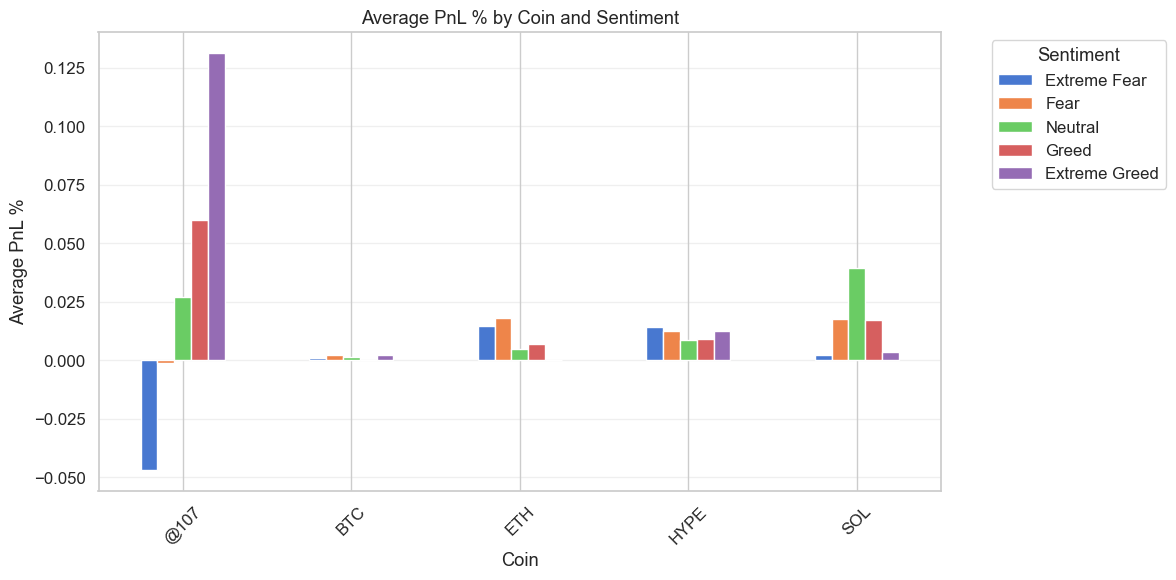

In [203]:
# Visualize
fig, ax = plt.subplots(figsize=(12, 6))
pnl_pivot = merged_df[merged_df['coin'].isin(top_5_coins)].pivot_table(
    values='pnl_pct', index='coin', columns='classification', aggfunc='mean'
)
pnl_pivot[sentiment_order].plot(kind='bar', ax=ax, rot=45)
ax.set_ylabel('Average PnL %')
ax.set_xlabel('Coin')
ax.set_title('Average PnL % by Coin and Sentiment')
ax.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/Coin_by_sentiment.png')
plt.show()

- @107 is extremely sentiment-sensitive; ETH favors fear, SOL favors neutrality.

- BTC and HYPE are sentiment-resilient.

#### Sentiment Transitions 

Analyzes what happens when market sentiment shifts (e.g., Fear → Greed)

In [204]:
# Create daily aggregated data
daily_data = merged_df.groupby('date').agg({
    'classification': 'first',  # Sentiment of the day
    'closed_pnl': 'sum',
    'pnl_pct': 'mean',
    'size_usd': 'sum',
    'is_profitable': 'mean'
}).reset_index()

# Add previous day sentiment
daily_data['prev_sentiment'] = daily_data['classification'].shift(1)

# Filter out first row (no previous day)
transitions = daily_data.dropna(subset=['prev_sentiment'])

# Analyze transitions
transition_perf = transitions.groupby(['prev_sentiment', 'classification']).agg({
    'pnl_pct': 'mean',
    'is_profitable': 'mean'
}).round(4)

print("\nPerformance After Sentiment Transitions:")
print("(Previous Day Sentiment → Current Day Sentiment)")
display(transition_perf)


Performance After Sentiment Transitions:
(Previous Day Sentiment → Current Day Sentiment)


pnl_pct  is_profitable
prev_sentiment classification                        
Extreme Fear   Extreme Fear     0.0137         0.4143
               Fear             0.0247         0.4184
               Neutral          0.0120         0.2986
Extreme Greed  Extreme Greed    0.0254         0.4616
               Greed            0.0237         0.4624
Fear           Extreme Fear    -0.0258         0.2404
               Fear             0.0136         0.3412
               Greed            0.0080         0.1383
               Neutral          0.0125         0.3668
Greed          Extreme Greed    0.0422         0.4897
               Fear             0.0328         0.2452
               Greed            0.0156         0.3351
               Neutral          0.0153         0.2859
Neutral        Fear             0.0092         0.2648
               Greed            0.0042         0.2445
               Neutral          0.0071         0.3405

This table shows how current trades perform based on the previous sentiment, revealing momentum and reversal patterns.

- Fear to Extreme Fear is catastrophic. This represents capitulation/panic selling - avoid trading when fear is intensifying. Staying in Fear or moving to Neutral is safer.

- Greed to Extreme Greed is powerful. Even Greed to Fear reversal works - suggesting profit-taking opportunities when sentiment flips.

- All transitions from Neutral are weak. Neutral represents indecision - wait for stronger directional signals.

#### Statistical Tests 

Proves whether the patterns are statistically significant or just random

In [205]:
from scipy import stats

# ANOVA test: Is there significant difference in PnL% across sentiments?
sentiment_groups = [group['pnl_pct'].values for name, group in merged_df.groupby('classification')]
f_stat, p_value = stats.f_oneway(*sentiment_groups)

print(f"\nANOVA Test - PnL% across sentiments:")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Result: {'SIGNIFICANT' if p_value < 0.05 else 'NOT SIGNIFICANT'} difference in profitability across sentiments")


ANOVA Test - PnL% across sentiments:
F-statistic: 9.1591
P-value: 0.000000
Result: SIGNIFICANT difference in profitability across sentiments


The differences in average PnL% we observed (Extreme Greed +4%, Neutral +1%, etc.) are NOT due to random chance. Sentiment genuinely impacts profitability.

In [206]:
# Chi-square test: Is win rate independent of sentiment?
contingency_table = pd.crosstab(merged_df['classification'], merged_df['is_profitable'])
chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nChi-Square Test - Win rate vs Sentiment:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_val:.6f}")
print(f"Result: Win rate is {'DEPENDENT' if p_val < 0.05 else 'INDEPENDENT'} of sentiment")


Chi-Square Test - Win rate vs Sentiment:
Chi-square statistic: 822.1103
P-value: 0.000000
Result: Win rate is DEPENDENT of sentiment


The variation in win rates (Extreme Greed 47%, Extreme Fear 37%, etc.) is NOT random. Sentiment systematically affects the probability of winning trades.